# Evaluation of LLM-Generated Usability Analysis

This notebook evaluates the perceived **plausibility** of usability issue descriptions and improvement recommendations generated by an LLM for product configurators.

### Scientific Reproducibility
To reproduce this analysis:
1. Ensure the `results/Evaluations.csv` and `results/Analysis_Results.csv` files are present in the same directory structure.
2. Install the required dependencies: `pip install -r requirements.txt`.
3. Run all cells in sequence.

The evaluation focuses on:
1. **Inter-Rater Reliability (IRR)**: Quantifying the agreement between human reviewers using Fleiss' Kappa and Gwet's AC1.
2. **Quantitative Accuracy**: Using majority voting to determine "Overall Perceived Plausibility."
3. **Breakdown Analysis**: Reviewing plausibility across usability criteria and severity levels.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")

## 1. Data Loading and Preparation
Load the evaluation results and the original analysis data. Map the categorical ratings ("Plausible", "Implausible") to numerical values for statistical analysis.


In [3]:
# Load datasets
eval_df = pd.read_csv('results/Evaluations.csv')
results_df = pd.read_csv('results/Analysis_Results.csv')

# Data Integrity Check
reviewer_counts = eval_df.groupby(['app_id', 'criterion_id']).size()
print(f"Total Unique Issues: {len(reviewer_counts)}")
print(f"Issues with exactly 3 reviews: {(reviewer_counts == 3).sum()}")

# Map ratings to binary
mapping = {"Plausible": 1, "Implausible": 0}
eval_df['error_num'] = eval_df['plausible_error'].map(mapping)
eval_df['rec_num'] = eval_df['plausible_recommendation'].map(mapping)

# Display basic info
print(f"Total Individual Evaluations: {len(eval_df)}")

Total Unique Issues: 148
Issues with exactly 3 reviews: 148
Total Individual Evaluations: 444


## 2. Inter-Rater Reliability (IRR)
Measure the agreement between reviewers. **Fleiss' Kappa** (standard metric) and **Gwet's AC1** (a more robust measure for skewed data) are reported..

**Interpretation Guide for Kappa/AC1:**
*   < 0: Poor agreement
*   0.01 – 0.20: Slight agreement
*   0.21 – 0.40: Fair agreement
*   0.41 – 0.60: Moderate agreement
*   0.61 – 0.80: Substantial agreement
*   0.81 – 1.00: Almost perfect agreement

### Inter-Rater Reliability Summary
                      Metric Issue Description Recommendation
0    Observed Agreement (Po)             0.694          0.842
1                 Gwet's AC1             0.546          0.813
2              Fleiss' Kappa              0.06         -0.007
3   Chance Agreement (Kappa)             0.674          0.843
4  Perfect Agreement (All 3)             54.1%          76.4%

### Consensus Breakdown (Agreement Ratio)
Issue Description:
 3    0.541
2    0.459
Name: proportion, dtype: float64

Recommendation:
 3    0.764
2    0.236
Name: proportion, dtype: float64


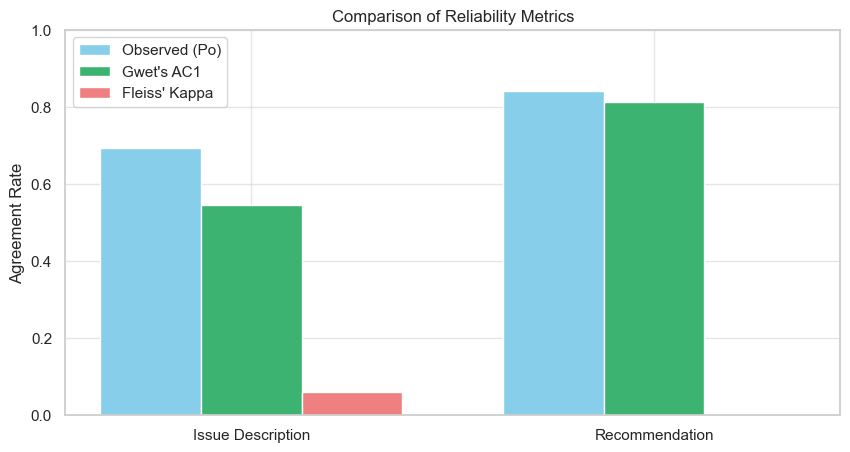

In [4]:
def calculate_irr(df, column):
    # Filter for items with > 1 review to calculate IRR
    issue_counts = df.groupby(['app_id', 'criterion_id']).size()
    multi_review_issues = issue_counts[issue_counts > 1].index
    
    if len(multi_review_issues) == 0:
        return {k: np.nan for k in ['kappa', 'ac1', 'po', 'pe_kappa', 'pe_ac1', 'perfect_agreement', 'dist']}
    
    subset = df.set_index(['app_id', 'criterion_id']).loc[multi_review_issues]
    
    # Create rating matrix
    rating_matrix = subset.groupby(['app_id', 'criterion_id'])[column].value_counts().unstack(fill_value=0)
    for val in [0, 1]:
        if val not in rating_matrix.columns: rating_matrix[val] = 0
            
    matrix = rating_matrix[[0, 1]].values
    n, q = matrix.shape
    r = matrix.sum(axis=1)[0]
    
    # Observed agreement (Po)
    p_i = (np.sum(matrix**2, axis=1) - r) / (r * (r - 1))
    p_o = np.mean(p_i)
    
    # Fleiss' Kappa Chance Agreement (Pe_kappa)
    p_j = np.sum(matrix, axis=0) / (n * r)
    p_e_kappa = np.sum(p_j**2)
    kappa = (p_o - p_e_kappa) / (1 - p_e_kappa)
    
    # Gwet's AC1 Chance Agreement (Pe_ac1)
    # For binary: 2 * p * (1-p)
    p_e_ac1 = 2 * p_j[0] * p_j[1]
    ac1 = (p_o - p_e_ac1) / (1 - p_e_ac1)
    
    # Percent Agreement (All raters agree)
    perfect_agreement = (rating_matrix.max(axis=1) == r).mean()

    # Agreement Distribution
    dist = rating_matrix.max(axis=1).value_counts(normalize=True).sort_index(ascending=False)
    
    return {
        'kappa': kappa,
        'ac1': ac1,
        'po': p_o,
        'pe_kappa': p_e_kappa,
        'pe_ac1': p_e_ac1,
        'perfect_agreement': perfect_agreement,
        'dist': dist
    }

irr_err = calculate_irr(eval_df, 'error_num')
irr_rec = calculate_irr(eval_df, 'rec_num')

irr_summary = pd.DataFrame({
    "Metric": ["Observed Agreement (Po)", "Gwet's AC1", "Fleiss' Kappa", "Chance Agreement (Kappa)", "Perfect Agreement (All 3)"],
    "Issue Description": [irr_err['po'], irr_err['ac1'], irr_err['kappa'], irr_err['pe_kappa'], irr_err['perfect_agreement']],
    "Recommendation": [irr_rec['po'], irr_rec['ac1'], irr_rec['kappa'], irr_rec['pe_kappa'], irr_rec['perfect_agreement']]
})

# Apply rounding for cleaner summary table display
# Create a copy and ensure object type for string formatting
irr_summary_display = irr_summary.copy().astype(object)
irr_summary_display.iloc[0:4, 1:] = irr_summary_display.iloc[0:4, 1:].astype(float).round(3)
irr_summary_display.iloc[4, 1:] = irr_summary_display.iloc[4, 1:].astype(float).map(lambda x: f"{x:.1%}")

print("### Inter-Rater Reliability Summary")
print(irr_summary_display)

print("\n### Consensus Breakdown (Agreement Ratio)")
print("Issue Description:\n", irr_err['dist'].round(3))
print("\nRecommendation:\n", irr_rec['dist'].round(3))

# Visualizing Comparison
plt.figure(figsize=(10, 5))
labels = ['Issue Description', 'Recommendation']
x = np.arange(len(labels))
width = 0.25

plt.bar(x - width, [irr_err['po'], irr_rec['po']], width, label='Observed (Po)', color='skyblue')
plt.bar(x, [irr_err['ac1'], irr_rec['ac1']], width, label='Gwet\'s AC1', color='mediumseagreen')
plt.bar(x + width, [irr_err['kappa'], irr_rec['kappa']], width, label='Fleiss\' Kappa', color='lightcoral')

plt.ylabel('Agreement Rate')
plt.title('Comparison of Reliability Metrics')
plt.xticks(x, labels)
plt.legend()
plt.ylim(0, 1.0)
plt.show()


## 3. Quantitative Accuracy (Majority Vote)
Multiple reviews are aggregated into a single "Overall Plausibility" label using majority voting. As all items are reviewed by 3 persons, there are no draws.



In [5]:
# Aggregate ratings by issue
aggregated = eval_df.groupby(['app_id', 'criterion_id', 'criterion', 'severity']).agg({
    'error_num': 'mean',
    'rec_num': 'mean'
}).reset_index()

# Determine Majority Vote
aggregated['is_plausible_error'] = aggregated['error_num'] >= 0.5
aggregated['is_plausible_rec'] = aggregated['rec_num'] >= 0.5

# Calculate Overall Plausibility Rates
overall_error_acc = aggregated['is_plausible_error'].mean()
overall_rec_acc = aggregated['is_plausible_rec'].mean()

print(f"Overall Plausibility Rate (Descriptions): {overall_error_acc:.1%}")
print(f"Overall Plausibility Rate (Recommendations): {overall_rec_acc:.1%}")


Overall Plausibility Rate (Descriptions): 88.5%
Overall Plausibility Rate (Recommendations): 98.0%


## 4. Breakdown Analysis
Analyzing performance across different usability criteria and severity levels.


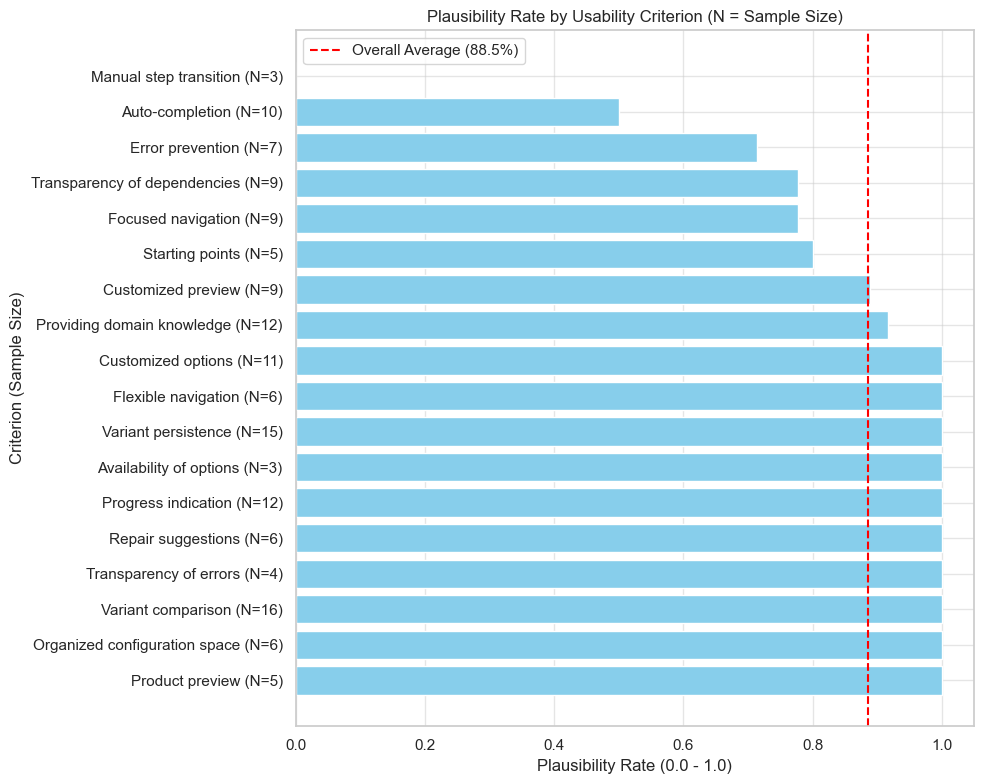


### Plausibility by Severity
             is_plausible_error  is_plausible_rec   N
severity                                             
Major Issue               0.893             0.987  75
Minor Issue               0.877             0.973  73


In [6]:
# Plausibility per Criterion
crit_stats = aggregated.groupby('criterion').agg(
    plausibility_rate=('is_plausible_error', 'mean'),
    sample_size=('is_plausible_error', 'count')
).sort_values(by='plausibility_rate', ascending=False)

# Create labels with sample sizes
labels = [f"{idx} (N={int(row['sample_size'])})" for idx, row in crit_stats.iterrows()]

plt.figure(figsize=(10, 8))
plt.barh(labels, crit_stats['plausibility_rate'], color='skyblue')
plt.title('Plausibility Rate by Usability Criterion (N = Sample Size)')
plt.xlabel('Plausibility Rate (0.0 - 1.0)')
plt.ylabel('Criterion (Sample Size)')
plt.axvline(x=overall_error_acc, color='red', linestyle='--', label=f'Overall Average ({overall_error_acc:.1%})')
plt.legend()
plt.tight_layout()
plt.show()

# Plausibility per Severity
sev_acc = aggregated.groupby('severity')[['is_plausible_error', 'is_plausible_rec']].mean().round(3)
sev_counts = aggregated.groupby('severity').size()
sev_summary = sev_acc.copy()
sev_summary['N'] = sev_counts

print("\n### Plausibility by Severity")
print(sev_summary)
